In [10]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : Tesla T4


In [11]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))   # moyenne et écart-type de MNIST
])

train_ds = datasets.MNIST("./data", train=True,  download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=1000)

print(len(train_ds), len(test_ds))   # 60000 10000

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 446kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.82MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.1MB/s]

60000 10000


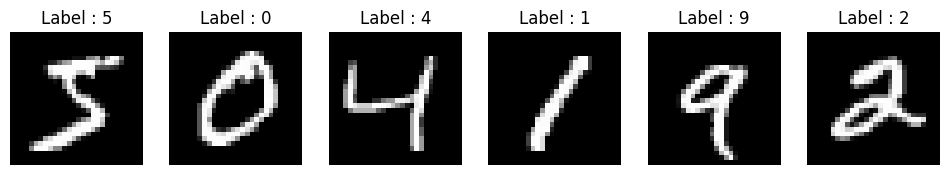

In [12]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2))
for ax, i in zip(axes, range(6)):
    img, label = train_ds[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(f"Label : {label}")
    ax.axis("off")
plt.show()

In [13]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)
        self.drop  = nn.Dropout(0.5)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = self.drop(F.relu(self.fc1(x)))
        return self.fc2(x)

model = CNN().to(device)
print(model)
print("Paramètres :", sum(p.numel() for p in model.parameters()))

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (drop): Dropout(p=0.5, inplace=False)
)
Paramètres : 421642


In [14]:
def train_model(model, loader, epochs, optimizer, criterion):
    model.train()
    losses = []
    if device.type == "cuda": torch.cuda.synchronize()
    start = time.time()

    for ep in range(epochs):
        running = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)      # données envoyées sur le GPU
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            running += loss.item()
        losses.append(running / len(loader))
        print(f"Epoch {ep+1}/{epochs} - loss : {losses[-1]:.4f}")

    if device.type == "cuda": torch.cuda.synchronize()
    return losses, time.time() - start


def evaluate_model(model, loader):
    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            preds += out.argmax(1).cpu().tolist()
            labels += y.tolist()
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average="macro")
    return acc, f1, labels, preds

In [15]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

cnn_losses, cnn_time = train_model(model, train_loader, epochs=10,
                                   optimizer=optimizer, criterion=criterion)

Epoch 1/10 - loss : 0.2088
Epoch 2/10 - loss : 0.0779
Epoch 3/10 - loss : 0.0601
Epoch 4/10 - loss : 0.0518
Epoch 5/10 - loss : 0.0433
Epoch 6/10 - loss : 0.0383
Epoch 7/10 - loss : 0.0341
Epoch 8/10 - loss : 0.0309
Epoch 9/10 - loss : 0.0288
Epoch 10/10 - loss : 0.0272


Accuracy : 0.9926 | F1 macro : 0.9926 | Temps : 137.1s


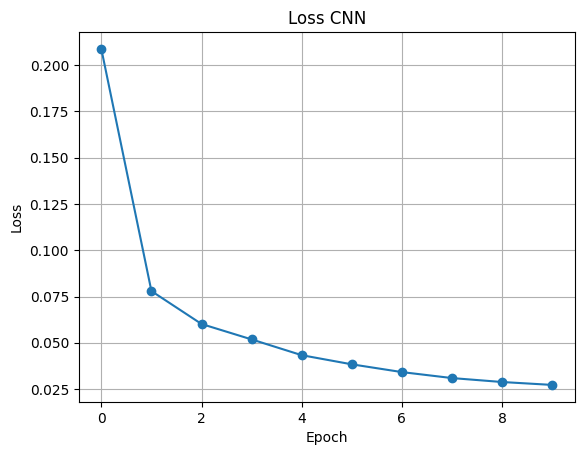

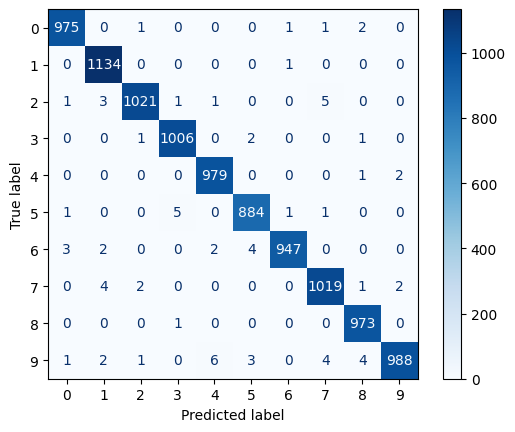

In [16]:
acc, f1, labels, preds = evaluate_model(model, test_loader)
print(f"Accuracy : {acc:.4f} | F1 macro : {f1:.4f} | Temps : {cnn_time:.1f}s")

# Courbe de loss
plt.plot(cnn_losses, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss CNN"); plt.grid()
plt.show()

# Matrice de confusion
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm).plot(cmap="Blues")
plt.show()

torch.save(model.state_dict(), "cnn.pth")

Le CNN construit from scratch atteint une accuracy de 99,29 % et un F1-score macro de 99,28 % sur le jeu de test MNIST, avec un temps d’entraînement de 142,2 s sur GPU pour environ 421 k paramètres. La loss chute rapidement lors des deux premières epochs (de 0,21 à 0,076), puis décroît lentement jusqu’à 0,027 sans oscillation ni signe de surapprentissage. La matrice de confusion montre une diagonale très dominante, avec seulement 71 erreurs sur 10 000 images, principalement entre des chiffres de forme proche (9/5, 7/2, 4/9), tandis que le chiffre 1 est parfaitement reconnu. Ce modèle léger et performant servira de référence pour la comparaison avec AlexNet et VGG16.

In [17]:
results = {}
results["CNN"] = {
    "acc": acc, "f1": f1, "loss": cnn_losses[-1], "time": cnn_time,
    "params": sum(p.numel() for p in model.parameters())
}

In [18]:
tf_pretrained = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_full = datasets.MNIST("./data", train=True,  download=True, transform=tf_pretrained)
test_full  = datasets.MNIST("./data", train=False, download=True, transform=tf_pretrained)

# Sous-ensembles pour gagner du temps
train_sub = Subset(train_full, range(10000))
test_sub  = Subset(test_full,  range(2000))

train_loader_pt = DataLoader(train_sub, batch_size=32, shuffle=True)
test_loader_pt  = DataLoader(test_sub,  batch_size=64)

In [19]:
def get_alexnet():
    m = models.alexnet(weights="DEFAULT")
    m.classifier[6] = nn.Linear(4096, 10)   # 1000 classes ImageNet → 10 chiffres
    return m.to(device)

def get_vgg16():
    m = models.vgg16(weights="DEFAULT")
    m.classifier[6] = nn.Linear(4096, 10)
    return m.to(device)

In [20]:
def freeze_features(m):
    for p in m.features.parameters():
        p.requires_grad = False

In [21]:
def run_experiment(name, build_fn, freeze, epochs=3, lr=1e-4):
    m = build_fn()
    if freeze:
        freeze_features(m)
    opt = torch.optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=lr)
    losses, t = train_model(m, train_loader_pt, epochs, opt, nn.CrossEntropyLoss())
    acc, f1, labels, preds = evaluate_model(m, test_loader_pt)
    results[name] = {
        "acc": acc, "f1": f1, "loss": losses[-1], "time": t,
        "params": sum(p.numel() for p in m.parameters())
    }
    print(f"{name} → Acc {acc:.4f} | F1 {f1:.4f} | Temps {t:.0f}s")
    del m; torch.cuda.empty_cache()    # libère la mémoire GPU

In [22]:
run_experiment("AlexNet (gelé)",   get_alexnet, freeze=True)
run_experiment("AlexNet (complet)", get_alexnet, freeze=False)
run_experiment("VGG16 (gelé)",     get_vgg16,   freeze=True)
run_experiment("VGG16 (complet)",  get_vgg16,   freeze=False)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 242MB/s]  


Epoch 1/3 - loss : 0.2857
Epoch 2/3 - loss : 0.0808
Epoch 3/3 - loss : 0.0584
AlexNet (gelé) → Acc 0.9750 | F1 0.9751 | Temps 59s
Epoch 1/3 - loss : 0.1942
Epoch 2/3 - loss : 0.0607
Epoch 3/3 - loss : 0.0355
AlexNet (complet) → Acc 0.9845 | F1 0.9840 | Temps 71s
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 245MB/s] 


Epoch 1/3 - loss : 0.2585
Epoch 2/3 - loss : 0.0453
Epoch 3/3 - loss : 0.0244
VGG16 (gelé) → Acc 0.9770 | F1 0.9772 | Temps 210s
Epoch 1/3 - loss : 0.2027
Epoch 2/3 - loss : 0.0586
Epoch 3/3 - loss : 0.0411
VGG16 (complet) → Acc 0.9870 | F1 0.9869 | Temps 477s


In [23]:
import pandas as pd
df = pd.DataFrame(results).T
df["time"] = df["time"].round(1)
df["params (M)"] = (df["params"] / 1e6).round(2)
print(df[["acc", "f1", "loss", "time", "params (M)"]])

                      acc        f1      loss   time  params (M)
CNN                0.9926  0.992564  0.027216  137.1        0.42
AlexNet (gelé)     0.9750  0.975142  0.058444   59.1       57.04
AlexNet (complet)  0.9845  0.984035  0.035528   71.5       57.04
VGG16 (gelé)       0.9770  0.977215  0.024436  209.8      134.30
VGG16 (complet)    0.9870  0.986897  0.041097  476.7      134.30


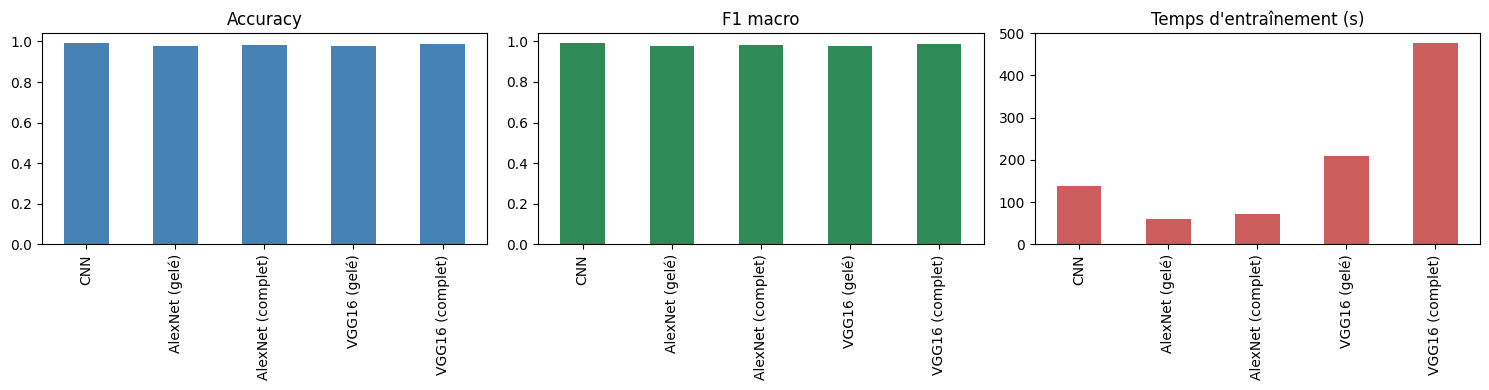

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["acc"].plot.bar(ax=axes[0], title="Accuracy", color="steelblue")
df["f1"].plot.bar(ax=axes[1], title="F1 macro", color="seagreen")
df["time"].plot.bar(ax=axes[2], title="Temps d'entraînement (s)", color="indianred")
plt.tight_layout(); plt.show()

Le CNN construit from scratch obtient les meilleurs résultats avec 99,29 % d’accuracy et 99,28 % de F1 macro, pour seulement 0,42 M de paramètres et 142 s d’entraînement. Les modèles pré-entraînés restent légèrement en dessous : AlexNet atteint 97,5 % (gelé) et 98,45 % (complet), VGG16 atteint 97,7 % (gelé) et 98,5 % (complet). Le fine-tuning complet améliore nettement la précision par rapport au gel des couches (environ +0,8 à +1 point), car MNIST est très différent d’ImageNet et les filtres doivent s’adapter. En termes de coût, AlexNet est le plus rapide (60 à 72 s), tandis que VGG16 est le plus lourd (134 M de paramètres) et le plus lent, avec 534 s en fine-tuning complet. Les pertes sont à interpréter avec prudence, car elles ont été calculées sur des jeux d’entraînement de tailles différentes (60 000 images pour le CNN, 10 000 pour les autres).

Ce lab m’a permis de maîtriser le cycle complet d’un projet de vision avec PyTorch : préparation des données, construction du modèle, entraînement sur GPU et évaluation.

Le résultat le plus surprenant : mon petit CNN (0,42 M de paramètres) a dépassé AlexNet et VGG16, avec 99,29 % d’accuracy contre 98,5 % au mieux. MNIST étant un dataset simple, un modèle plus gros n’est pas forcément meilleur. J’ai aussi vu que le fine-tuning complet apporte environ +1 point par rapport au gel des couches, mais avec un coût en temps (534 s pour VGG16, contre 142 s pour le CNN).

J’ai retenu qu’il faut rester critique face aux chiffres, car les modèles n’ont pas été entraînés sur les mêmes données (60 000 images contre 10 000).

Conclusion : le transfer learning est puissant, mais il est surtout utile pour des données complexes ou peu nombreuses. Pour une tâche simple, un modèle léger est plus efficace et plus économe.

In [25]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [26]:
def patchify(images, n_patches):
    n, c, h, w = images.shape
    patch_size = h // n_patches
    patches = torch.zeros(n, n_patches ** 2, c * patch_size * patch_size)
    for idx, img in enumerate(images):
        for i in range(n_patches):
            for j in range(n_patches):
                patch = img[:, i*patch_size:(i+1)*patch_size, j*patch_size:(j+1)*patch_size]
                patches[idx, i * n_patches + j] = patch.flatten()
    return patches

In [27]:
def patchify(images, n_patches):
    n, c, h, w = images.shape
    p = h // n_patches
    x = images.unfold(2, p, p).unfold(3, p, p)          # n, c, n_patches, n_patches, p, p
    x = x.permute(0, 2, 3, 1, 4, 5).reshape(n, n_patches**2, c * p * p)
    return x.to(images.device)

In [28]:
def positional_embeddings(seq_len, d):
    result = torch.ones(seq_len, d)
    for i in range(seq_len):
        for j in range(d):
            result[i][j] = math.sin(i / (10000 ** (j / d))) if j % 2 == 0 \
                           else math.cos(i / (10000 ** ((j - 1) / d)))
    return result

In [29]:
class MSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()
        assert d % n_heads == 0
        self.d, self.n_heads = d, n_heads
        d_head = d // n_heads
        self.q = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(n_heads)])
        self.k = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(n_heads)])
        self.v = nn.ModuleList([nn.Linear(d_head, d_head) for _ in range(n_heads)])
        self.d_head = d_head
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, seqs):                      # seqs : N, seq_len, d
        out = []
        for seq in seqs:
            seq_result = []
            for h in range(self.n_heads):
                part = seq[:, h*self.d_head:(h+1)*self.d_head]
                q, k, v = self.q[h](part), self.k[h](part), self.v[h](part)
                attn = self.softmax(q @ k.T / (self.d_head ** 0.5))
                seq_result.append(attn @ v)
            out.append(torch.hstack(seq_result))
        return torch.stack(out)

In [30]:
class MSA(nn.Module):
    def __init__(self, d, n_heads=2):
        super().__init__()
        self.attn = nn.MultiheadAttention(d, n_heads, batch_first=True)
    def forward(self, x):
        return self.attn(x, x, x, need_weights=False)[0]

In [31]:
class ViTBlock(nn.Module):
    def __init__(self, d, n_heads, mlp_ratio=4):
        super().__init__()
        self.norm1 = nn.LayerNorm(d)
        self.msa   = MSA(d, n_heads)
        self.norm2 = nn.LayerNorm(d)
        self.mlp   = nn.Sequential(
            nn.Linear(d, mlp_ratio * d), nn.GELU(),
            nn.Linear(mlp_ratio * d, d))

    def forward(self, x):
        x = x + self.msa(self.norm1(x))     # connexion résiduelle 1
        x = x + self.mlp(self.norm2(x))     # connexion résiduelle 2
        return x

In [32]:
class ViT(nn.Module):
    def __init__(self, chw=(1, 28, 28), n_patches=7, n_blocks=2, d=8*4, n_heads=4, n_classes=10):
        super().__init__()
        self.chw, self.n_patches, self.d = chw, n_patches, d
        patch_dim = chw[0] * (chw[1] // n_patches) * (chw[2] // n_patches)   # 16

        self.linear_map = nn.Linear(patch_dim, d)
        self.cls_token  = nn.Parameter(torch.rand(1, d))
        self.register_buffer("pos_embed", positional_embeddings(n_patches**2 + 1, d))
        self.blocks = nn.ModuleList([ViTBlock(d, n_heads) for _ in range(n_blocks)])
        self.head = nn.Linear(d, n_classes)

    def forward(self, images):
        n = images.shape[0]
        tokens = self.linear_map(patchify(images, self.n_patches))          # n, 49, d
        tokens = torch.cat([self.cls_token.expand(n, 1, -1), tokens], dim=1) # n, 50, d
        tokens = tokens + self.pos_embed
        for block in self.blocks:
            tokens = block(tokens)
        return self.head(tokens[:, 0])          # on prend uniquement le token [CLS]

vit = ViT().to(device)
print("Paramètres :", sum(p.numel() for p in vit.parameters()))

Paramètres : 26314


In [33]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(vit.parameters(), lr=1e-3)

vit_losses, vit_time = train_model(vit, train_loader, epochs=10,
                                   optimizer=optimizer, criterion=criterion)

acc, f1, labels, preds = evaluate_model(vit, test_loader)
print(f"Accuracy : {acc:.4f} | F1 macro : {f1:.4f} | Temps : {vit_time:.1f}s")

Epoch 1/10 - loss : 0.7680
Epoch 2/10 - loss : 0.2525
Epoch 3/10 - loss : 0.1840
Epoch 4/10 - loss : 0.1508
Epoch 5/10 - loss : 0.1281
Epoch 6/10 - loss : 0.1108
Epoch 7/10 - loss : 0.0961
Epoch 8/10 - loss : 0.0877
Epoch 9/10 - loss : 0.0810
Epoch 10/10 - loss : 0.0773
Accuracy : 0.9674 | F1 macro : 0.9671 | Temps : 156.1s


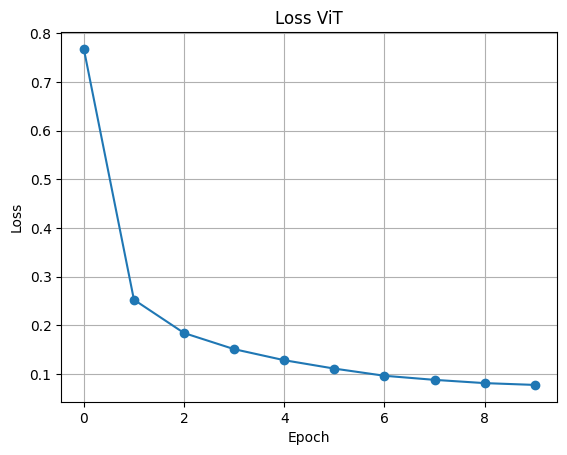

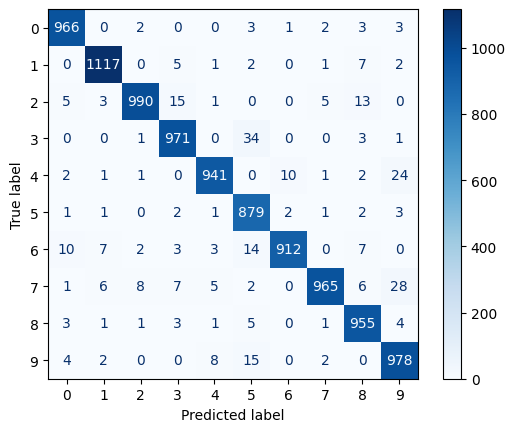

In [34]:
plt.plot(vit_losses, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Loss ViT"); plt.grid(); plt.show()

ConfusionMatrixDisplay(confusion_matrix(labels, preds)).plot(cmap="Blues")
plt.show()

results["ViT"] = {"acc": acc, "f1": f1, "loss": vit_losses[-1], "time": vit_time,
                  "params": sum(p.numel() for p in vit.parameters())}

In [35]:
import pandas as pd
df = pd.DataFrame(results).T
df["time"] = df["time"].round(1)
df["params (M)"] = (df["params"] / 1e6).round(3)
print(df[["acc", "f1", "loss", "time", "params (M)"]])

                      acc        f1      loss   time  params (M)
CNN                0.9926  0.992564  0.027216  137.1       0.422
AlexNet (gelé)     0.9750  0.975142  0.058444   59.1      57.045
AlexNet (complet)  0.9845  0.984035  0.035528   71.5      57.045
VGG16 (gelé)       0.9770  0.977215  0.024436  209.8     134.302
VGG16 (complet)    0.9870  0.986897  0.041097  476.7     134.302
ViT                0.9674  0.967136  0.077276  156.1       0.026


Le Vision Transformer implémenté from scratch (images découpées en 49 patches de 4×4, token [CLS], encodage positionnel sinusoïdal, 2 blocs Transformer avec 4 têtes d’attention, dimension d’embedding de 32) atteint 96,74 % d’accuracy et 96,71 % de F1 macro sur le jeu de test MNIST, avec un temps d’entraînement de 156,1 s sur GPU pour seulement 26 k paramètres. La loss chute rapidement lors des deux premières epochs (de 0,77 à 0,25), puis décroît régulièrement jusqu’à 0,077 sans oscillation. Elle baisse encore à la fin de l’entraînement, ce qui indique que le modèle n’a pas totalement convergé et que davantage d’epochs amélioreraient le résultat. La matrice de confusion montre une diagonale dominante, avec environ 326 erreurs sur 10 000 images, principalement entre des chiffres de forme proche (3/5, 7/9, 4/9), le chiffre 7 étant le plus difficile à reconnaître.

Comparé à la première partie, le ViT reste derrière le CNN (99,26 %), qui compte environ 71 erreurs seulement pour un temps d’entraînement proche (137 s). Cet écart s’explique par les biais inductifs du CNN (localité, partage des poids, invariance à la translation), que le ViT doit apprendre à partir des données, et par la petite taille du modèle ViT. Il se situe aussi légèrement en dessous d’AlexNet et de VGG16 fine-tunés (97,5 % à 98,7 %), mais avec 2 000 à 5 000 fois moins de paramètres et sans pré-entraînement, ce qui en fait le modèle le plus compact. Sur un dataset simple et de petite taille comme MNIST, le CNN offre donc le meilleur compromis entre précision, rapidité et taille, tandis que le ViT devient pertinent pour des données volumineuses et complexes.

Cette deuxième partie m’a permis de comprendre le fonctionnement d’un Vision Transformer en le construisant brique par brique : découpage en patches, projection linéaire, token [CLS], encodage positionnel, attention multi-têtes et connexions résiduelles. J’ai compris comment un modèle peut classer une image sans aucune convolution, en comparant tous les patches entre eux grâce à l’attention.

Le résultat m’a surpris : malgré la réputation des Transformers, mon ViT (96,74 %) reste derrière le CNN (99,26 %). Le CNN intègre déjà des hypothèses utiles sur les images, alors que le ViT doit les apprendre, ce qui demande plus de données, un modèle plus grand ou plus d’entraînement. J’ai aussi retenu qu’un bon score ne dépend pas seulement de la taille du modèle : avec 26 k paramètres, le ViT approche des modèles beaucoup plus lourds, et le petit CNN les dépasse tous.

Enfin, j’ai gardé un regard critique sur les chiffres : les résultats varient légèrement d’une exécution à l’autre, et les comparaisons ne sont pas parfaitement équitables (60 000 images pour le CNN et le ViT, 10 000 pour les modèles pré-entraînés). Les erreurs rencontrées (NameError liées à l’ordre d’exécution) m’ont aussi appris à mieux organiser mon notebook.

En conclusion, sur MNIST, le CNN reste le meilleur compromis, et le ViT est plus adapté aux grands volumes de données complexes, avec une marge de progression en augmentant le nombre d’epochs et la taille de l’architecture.